# Notebook 01 — Business Understanding, Data Gathering, EDA, dan Cleaning

Jalankan notebook dari atas ke bawah. Data diambil dari sumber UCI resmi saat notebook dijalankan, atau dibaca dari `data/raw/student-mat.csv` jika file tersedia. Hasil analisis baru dianggap final setelah semua sel dijalankan dan diperiksa.

# Proyek Akhir Praktikum Data Science
## Prediksi Nilai Akhir Matematika Siswa Menggunakan Data Sosial, Keluarga, dan Sekolah

**Metode:** Regresi  
**Dataset:** UCI Student Performance — berkas `student-mat.csv`  
**Kerangka kerja:** CRISP-DM

> **Catatan:** Notebook ini dirancang untuk dijalankan berurutan dari atas ke bawah. Dataset akan diunduh dari UCI melalui URL berkas resmi. Jika akses internet atau unduhan tidak tersedia, unduh `student-mat.csv` dari [halaman UCI](https://archive.ics.uci.edu/dataset/320/student%2Bperformance) dan letakkan di folder yang sama dengan notebook. Hasil metrik akan dihitung saat notebook dijalankan; angka hasil tidak ditulis seolah-olah sudah diuji di lingkungan ini.


## 1. Business Understanding

### 1.1 Latar belakang
Nilai akhir siswa dapat berkaitan dengan berbagai faktor, seperti waktu belajar, riwayat kegagalan kelas, dukungan keluarga, dan kondisi sekolah. Analisis ini mencoba memperkirakan nilai akhir Matematika (`G3`) berdasarkan fitur non-nilai agar model tidak bergantung pada nilai periode sebelumnya.

### 1.2 Rumusan masalah
1. Seberapa baik model regresi dapat memperkirakan nilai akhir Matematika (`G3`) dari fitur yang tersedia?
2. Model mana yang memberikan hasil prediksi lebih baik pada data uji?
3. Fitur apa yang paling berkontribusi terhadap prediksi model?

### 1.3 Tujuan
Membangun dan membandingkan beberapa model regresi, mengevaluasi performanya dengan MAE, RMSE, dan R², serta mengidentifikasi fitur penting sebagai bahan eksplorasi.

### 1.4 Target dan metrik
- **Target:** `G3`, nilai akhir Matematika pada skala 0–20.
- **Metrik utama:** MAE dan RMSE (lebih rendah lebih baik), serta R² (lebih tinggi umumnya lebih baik).
- **Model pembanding:** Dummy Regressor sebagai baseline, Linear Regression, dan Random Forest Regressor.

### 1.5 Batasan dan etika
Data berasal dari dua sekolah di Portugal dan tidak otomatis mewakili sekolah di Indonesia. Model hanya digunakan untuk pembelajaran dan eksplorasi, bukan untuk memberi label atau mengambil keputusan penting terhadap siswa. Atribut yang tersedia bersifat asosiatif; feature importance tidak membuktikan hubungan sebab-akibat. `G1` dan `G2` dikeluarkan agar fokus pada perkiraan yang tidak menggunakan nilai periode sebelumnya. Ketersediaan waktu fitur seperti `absences` dan `failures` perlu dipertimbangkan bila model dimaksudkan untuk deteksi dini.


## 2. Data Gathering

Dataset Student Performance disediakan oleh UCI Machine Learning Repository. Data dikumpulkan dari laporan sekolah dan kuesioner siswa di dua sekolah menengah Portugal. Tersedia berkas untuk Matematika (`student-mat.csv`) dan Bahasa Portugis (`student-por.csv`); notebook ini menggunakan Matematika.

- Sumber: https://archive.ics.uci.edu/dataset/320/student%2Bperformance
- Sitasi dataset: Cortez, P. (2008). *Student Performance* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T
- Lisensi: CC BY 4.0 (berikan atribusi saat membagikan ulang atau mengadaptasi data).
- Unit observasi: satu baris mewakili satu siswa pada mata pelajaran Matematika.

Target `G3` adalah nilai akhir 0–20. `G1` dan `G2` merupakan nilai periode sebelumnya dan sengaja dikeluarkan dari fitur untuk mengurangi kebocoran informasi terhadap target.


In [1]:
# Impor pustaka
import os
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)

print("Pustaka berhasil diimpor.")


Pustaka berhasil diimpor.


In [2]:
# Memuat dataset dari satu lokasi standar di root proyek.
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
raw_dir = ROOT / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)
data_path = raw_dir / "student-mat.csv"
if not data_path.exists():
    url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    zip_path = raw_dir / "student-performance.zip"
    try:
        urllib.request.urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path, "r") as zf:
            member = next((m for m in zf.namelist() if m.endswith("student-mat.csv")), None)
            if member is None:
                raise FileNotFoundError("student-mat.csv tidak ditemukan di arsip UCI.")
            data_path.write_bytes(zf.read(member))
    except Exception as e:
        raise RuntimeError(
            f"Dataset tidak tersedia di {data_path} dan unduhan UCI gagal. "
            "Letakkan student-mat.csv di folder data/raw/."
        ) from e

df_raw = pd.read_csv(data_path, sep=";")
print("Sumber data:", data_path)
print("Ukuran data:", df_raw.shape)
display(df_raw.head())

Sumber data: c:\Users\LENOVO\OneDrive\Documents\Tugas Yasmine\Data Science\Proyek_Akhir_Data_Science_Student_Performance_Diperbaiki\Proyek_Akhir_Data_Science_Student_Performance\data\raw\student-mat.csv
Ukuran data: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


### 2.1 Memahami struktur data
Dataset Matematika umumnya memuat 395 baris dan 33 kolom, termasuk atribut demografis, keluarga, sekolah, dan tiga nilai periode (`G1`, `G2`, `G3`). Pemeriksaan di bawah menampilkan kondisi berkas yang benar-benar dimuat, sehingga perbedaan versi atau berkas dapat terdeteksi.


In [3]:
print("Jumlah baris dan kolom:", df_raw.shape)
print("\nNama kolom:")
print(df_raw.columns.tolist())
print("\nTipe data:")
display(df_raw.dtypes.rename("dtype").to_frame())
print("\nRingkasan statistik:")
display(df_raw.describe(include="all").T)


Jumlah baris dan kolom: (395, 33)

Nama kolom:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Tipe data:


,dtype
school,object
sex,object
age,int64
address,object
famsize,object
Pstatus,object
Medu,int64
Fedu,int64
Mjob,object
Fjob,object



Ringkasan statistik:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Exploratory Data Analysis (EDA)

EDA digunakan untuk melihat distribusi target, kondisi kualitas data, dan hubungan awal antara fitur dan nilai akhir. Insight harus dibaca berdasarkan grafik serta keluaran aktual setelah sel dijalankan.


In [4]:
# Pemeriksaan kualitas data sebelum pembersihan
missing_summary = df_raw.isna().sum().sort_values(ascending=False)
duplicate_count = df_raw.duplicated().sum()

print("Total missing values:", int(df_raw.isna().sum().sum()))
print("Baris duplikat penuh:", int(duplicate_count))
display(missing_summary[missing_summary > 0].rename("missing_count").to_frame())


Total missing values: 0
Baris duplikat penuh: 0


,missing_count


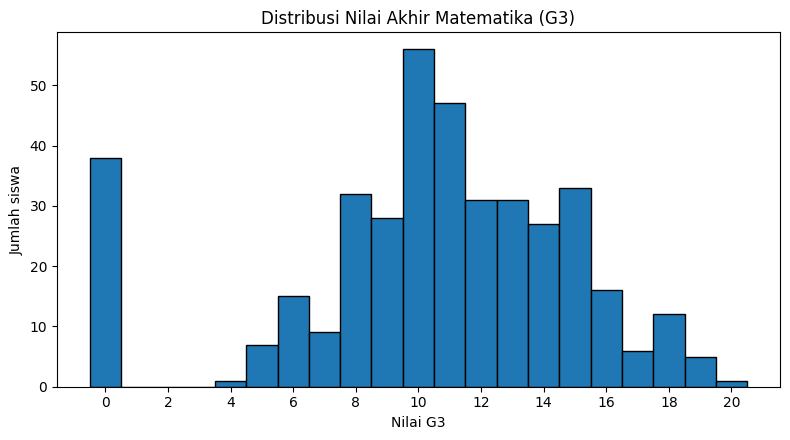

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64
Proporsi G3 < 10: 32.9%


In [5]:
# Distribusi target G3
plt.figure(figsize=(8, 4.5))
plt.hist(df_raw["G3"], bins=np.arange(-0.5, 21.5, 1), edgecolor="black")
plt.title("Distribusi Nilai Akhir Matematika (G3)")
plt.xlabel("Nilai G3")
plt.ylabel("Jumlah siswa")
plt.xticks(range(0, 21, 2))
plt.tight_layout()
plt.show()

print(df_raw["G3"].describe())
print("Proporsi G3 < 10: {:.1%}".format((df_raw["G3"] < 10).mean()))


**Cara membaca:** Histogram menunjukkan sebaran nilai akhir. Perhatikan apakah nilai terkonsentrasi pada rentang tertentu atau terdapat kelompok nilai yang tidak biasa. Proporsi `G3 < 10` merupakan deskripsi berdasarkan ambang analisis; ambang ini tidak boleh dianggap sebagai aturan kelulusan universal.


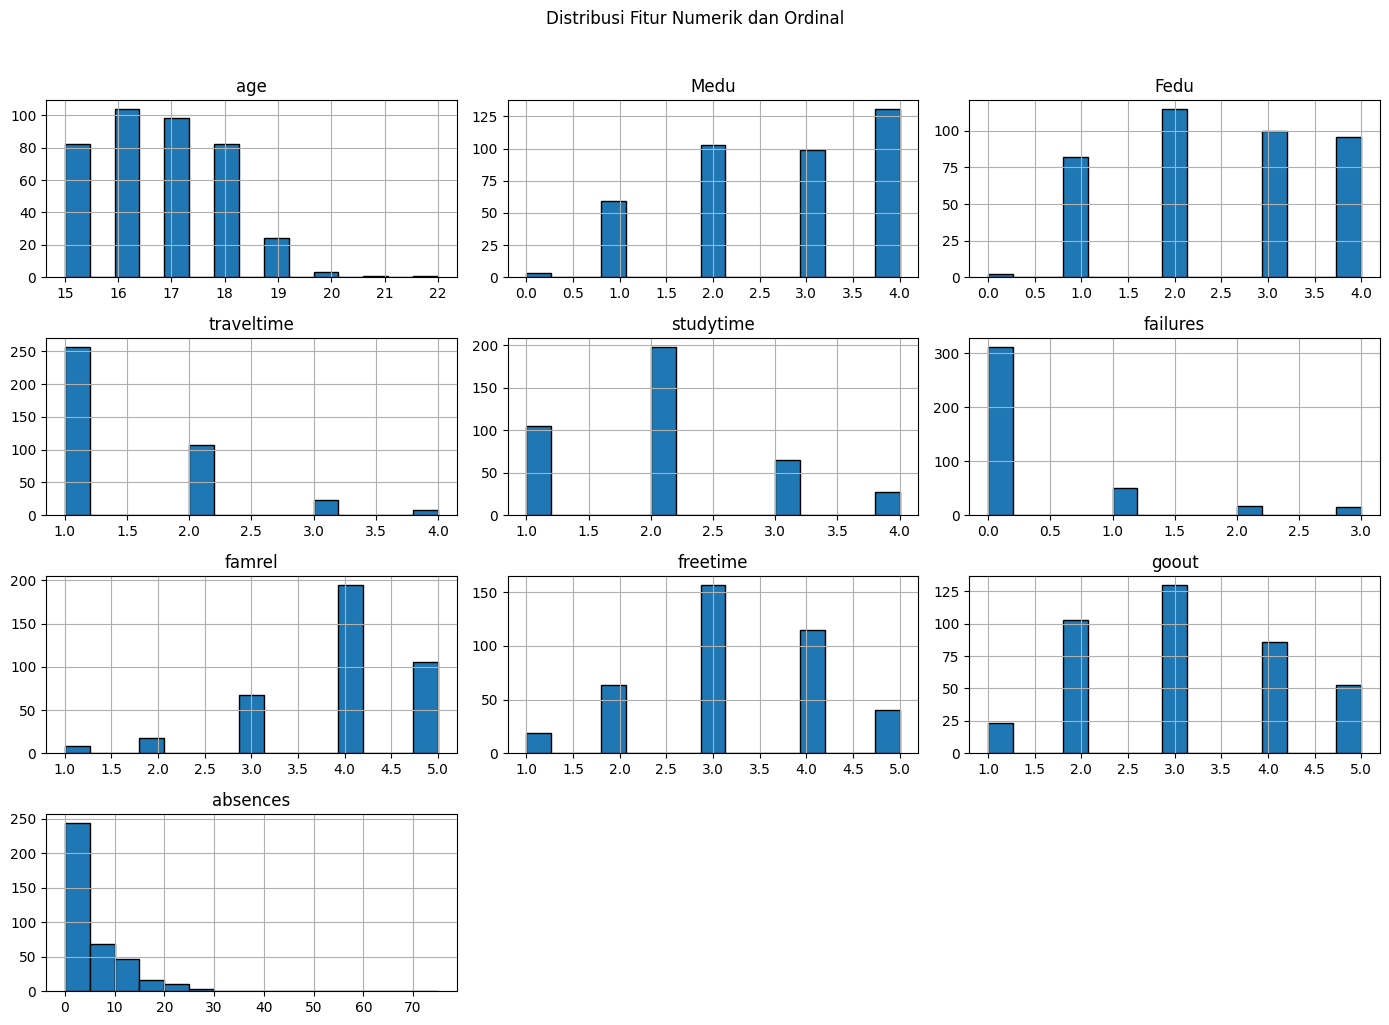

In [6]:
# Distribusi beberapa fitur numerik/ordinal
numeric_candidates = [
    c for c in ["age", "Medu", "Fedu", "traveltime", "studytime",
                "failures", "famrel", "freetime", "goout", "absences"]
    if c in df_raw.columns
]
df_raw[numeric_candidates].hist(figsize=(14, 10), bins=15, edgecolor="black")
plt.suptitle("Distribusi Fitur Numerik dan Ordinal", y=1.02)
plt.tight_layout()
plt.show()


**Cara membaca:** Grafik membantu menemukan fitur yang tidak seimbang atau condong, misalnya jumlah ketidakhadiran (`absences`) dan kegagalan kelas (`failures`). Nilai ekstrem perlu diperiksa konteksnya terlebih dahulu, bukan langsung dihapus.


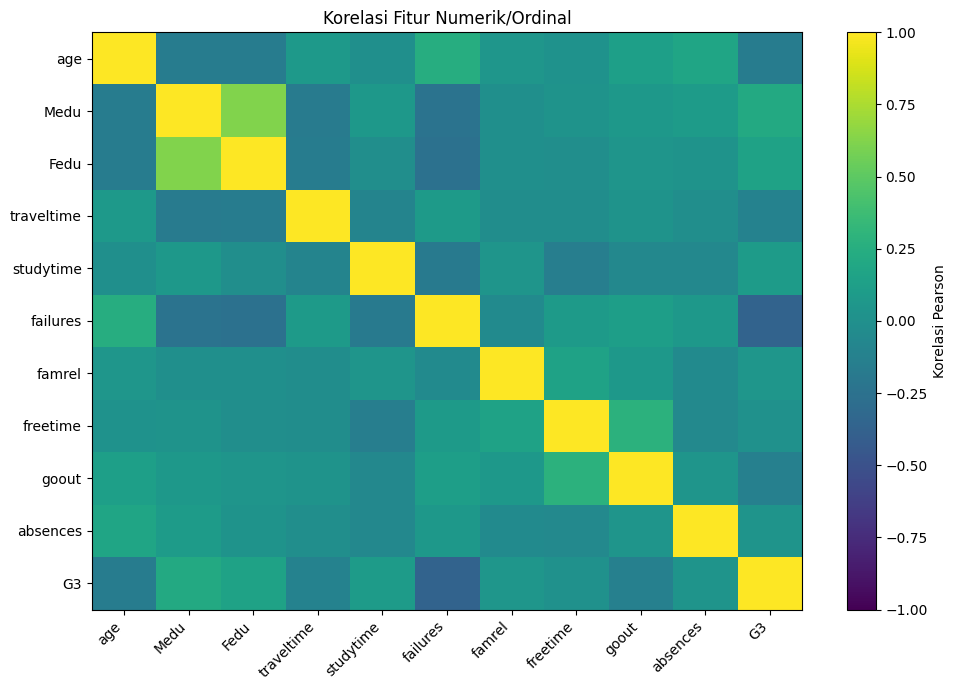

,G3
G3,1.000000
Medu,0.217147
Fedu,0.152457
studytime,0.097820
famrel,0.051363
absences,0.034247
freetime,0.011307
traveltime,-0.117142
goout,-0.132791
age,-0.161579


In [7]:
# Hubungan numerik/ordinal dengan target
corr_cols = [c for c in numeric_candidates + ["G3"] if c in df_raw.columns]
corr = df_raw[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Korelasi Pearson")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Korelasi Fitur Numerik/Ordinal")
plt.tight_layout()
plt.show()

display(corr[["G3"]].sort_values("G3", ascending=False))


**Cara membaca:** Korelasi menunjukkan hubungan linear, bukan sebab-akibat. `G1` dan `G2` dapat berkorelasi kuat dengan `G3`, tetapi keduanya tidak akan digunakan sebagai fitur model pada proyek ini. Untuk fitur ordinal seperti `studytime`, korelasi Pearson juga hanya memberi gambaran awal.


,count,mean,median
sex,,,
M,187,10.91,11.0
F,208,9.97,10.0


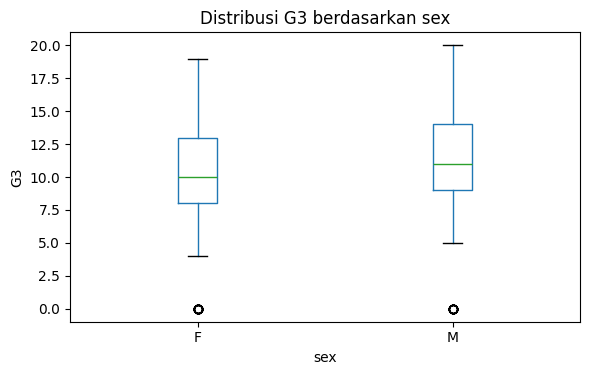

,count,mean,median
school,,,
GP,349,10.49,11.0
MS,46,9.85,10.0


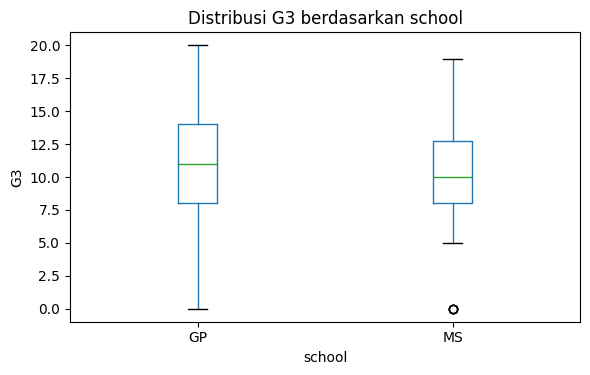

,count,mean,median
address,,,
U,307,10.67,11.0
R,88,9.51,10.0


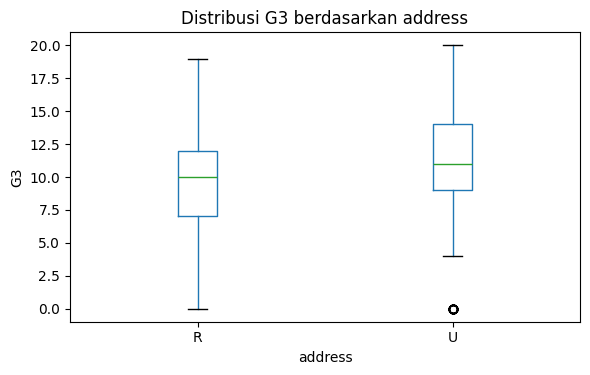

,count,mean,median
schoolsup,,,
no,344,10.56,11.0
yes,51,9.43,10.0


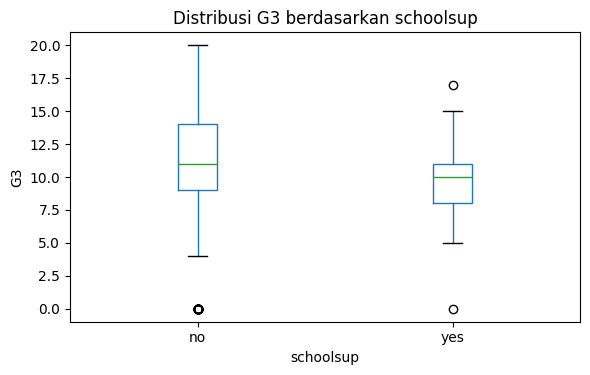

,count,mean,median
famsup,,,
no,153,10.64,11.0
yes,242,10.27,11.0


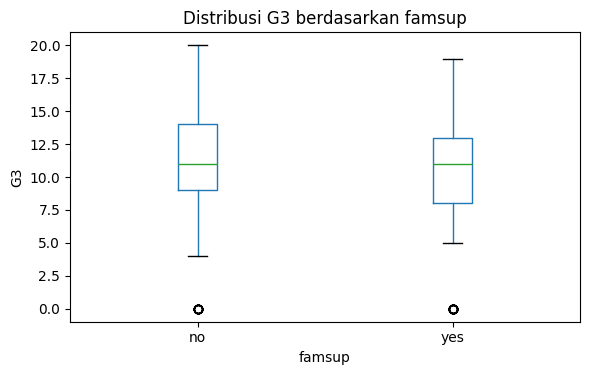

,count,mean,median
paid,,,
yes,181,10.92,11.0
no,214,9.99,11.0


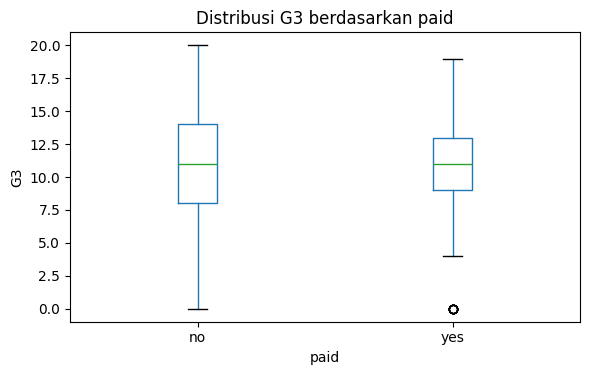

,count,mean,median
higher,,,
yes,375,10.61,11.0
no,20,6.80,8.0


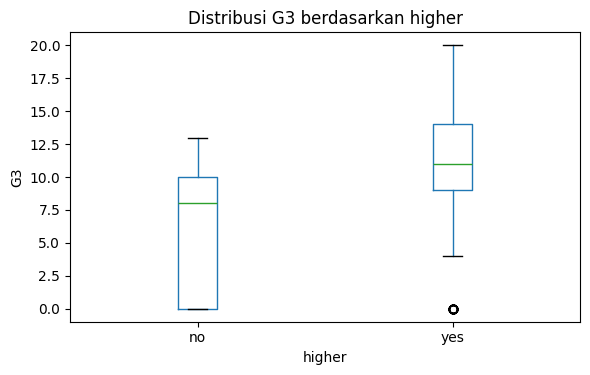

In [8]:
# Nilai G3 menurut beberapa fitur kategorikal
categorical_eda = [c for c in ["sex", "school", "address", "schoolsup",
                               "famsup", "paid", "higher"] if c in df_raw.columns]

for col in categorical_eda:
    grouped = df_raw.groupby(col, observed=False)["G3"].agg(["count", "mean", "median"])
    display(grouped.sort_values("mean", ascending=False).style.format({"mean": "{:.2f}", "median": "{:.1f}"}))

    ax = df_raw.boxplot(column="G3", by=col, figsize=(6, 4), grid=False)
    plt.title(f"Distribusi G3 berdasarkan {col}")
    plt.suptitle("")
    plt.xlabel(col)
    plt.ylabel("G3")
    plt.tight_layout()
    plt.show()


**Cara membaca:** Perbandingan kelompok dapat menunjukkan perbedaan rata-rata atau sebaran nilai pada sampel. Jangan menyimpulkan bahwa kategori tertentu menyebabkan nilai lebih tinggi/rendah; faktor lain dapat ikut berperan dan ukuran tiap kelompok bisa berbeda.


## 4. Cleaning dan Preprocessing

### 4.1 Pemeriksaan dan penanganan
Tahap ini memeriksa duplikasi, nilai kosong, tipe data, dan rentang target. Dataset UCI didokumentasikan tidak memiliki missing value, tetapi pengecekan tetap dilakukan pada berkas yang dimuat. Baris duplikat penuh dihapus bila ada. Nilai ekstrem tidak dihapus otomatis karena bisa merupakan observasi valid.


In [9]:
# Salin data agar data asli tetap tersedia untuk audit
df = df_raw.copy()
shape_before = df.shape
missing_before = int(df.isna().sum().sum())
duplicates_before = int(df.duplicated().sum())

df = df.drop_duplicates().copy()

# Pastikan target berupa numerik dan periksa baris dengan target tidak valid
df["G3"] = pd.to_numeric(df["G3"], errors="coerce")
invalid_target = df["G3"].isna() | ~df["G3"].between(0, 20)
invalid_target_count = int(invalid_target.sum())
df = df.loc[~invalid_target].copy()

print("Sebelum cleaning:", shape_before)
print("Missing sebelum:", missing_before)
print("Duplikat sebelum:", duplicates_before)
print("Target tidak valid yang dihapus:", invalid_target_count)
print("Sesudah cleaning:", df.shape)
print("Missing sesudah:", int(df.isna().sum().sum()))
print("Duplikat sesudah:", int(df.duplicated().sum()))


Sebelum cleaning: (395, 33)
Missing sebelum: 0
Duplikat sebelum: 0
Target tidak valid yang dihapus: 0
Sesudah cleaning: (395, 33)
Missing sesudah: 0
Duplikat sesudah: 0


### 4.2 Memeriksa nilai ekstrem
Outlier diperiksa pada `absences` dengan aturan IQR. Pemeriksaan ini hanya menandai kandidat outlier; nilai tidak dihapus secara otomatis karena jumlah ketidakhadiran yang tinggi mungkin benar-benar terjadi.


In [10]:
if "absences" in df.columns:
    q1 = df["absences"].quantile(0.25)
    q3 = df["absences"].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_mask = (df["absences"] < lower_bound) | (df["absences"] > upper_bound)

    print(f"Batas IQR: {lower_bound:.2f} sampai {upper_bound:.2f}")
    print("Jumlah kandidat outlier absences:", int(outlier_mask.sum()))
    display(df.loc[outlier_mask, ["absences", "G3"]].sort_values("absences", ascending=False).head(15))


Batas IQR: -12.00 sampai 20.00
Jumlah kandidat outlier absences: 15


,absences,G3
276,75,9
183,56,8
74,54,11
315,40,11
307,38,8
280,30,8
205,28,9
103,26,6
40,25,11
198,24,18
